# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

# 0.1 Мої відповіді:
##1. Чому для заповнення пропусків було обрано метод kNN?
Метод kNN дає змогу заповнювати пропущені значення на основі схожих записів у наборі даних. Це дозволяє враховувати взаємозв'язки між ознаками, а не просто замінювати пропуски середніми значеннями.
##2. Чому під час навчання train і val порівнюються за MSE, а після навчання використовуються інші метрики?
Під час навчання MSE використовується як функція втрат для оптимізації параметрів моделі. Після навчання додатково застосовуються RMSE, MAE та R² для комплексного оцінювання якості прогнозів.

Було перевірено три функції втрат:
- MSELoss: MSE = 0.55, RMSE = 0.74, MAE = 0.54, R² = 0.597.
- L1Loss: MSE = 0.60, RMSE = 0.78, MAE = 0.54, R² = 0.56.
- SmoothL1Loss: MSE = 0.599, RMSE = 0.77, MAE = 0.54, R² = 0.56.
Найкращі загальні результати показала MSELoss. При цьому L1Loss і SmoothL1Loss також можуть бути корисними залежно від особливостей завдання.
##3. Які висновки можна зробити після клітинки 2.6 у демо?
Найбільший вплив на прогноз мають ознаки MedInc, diag_coord і bedperroom, оскільки їхні коефіцієнти мають більші абсолютні значення. Інші ознаки мають менш виражений лінійний вплив. Водночас потрібно враховувати масштаби ознак.
##4. Для чого потрібен baseline у лінійній регресії та як він обчислюється? Що є baseline для нейронної мережі?
Baseline — це базовий результат для порівняння якості моделей. У цій роботі ним є лінійна регресія, якість якої оцінюється за метриками MSE, RMSE, MAE та R² на тестовій вибірці.

Для нейронної мережі baseline — це результат лінійної регресії. Якщо нейронна мережа має менші похибки та вище значення R² на тих самих тестових даних, її прогнозування є точнішим.

##5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.

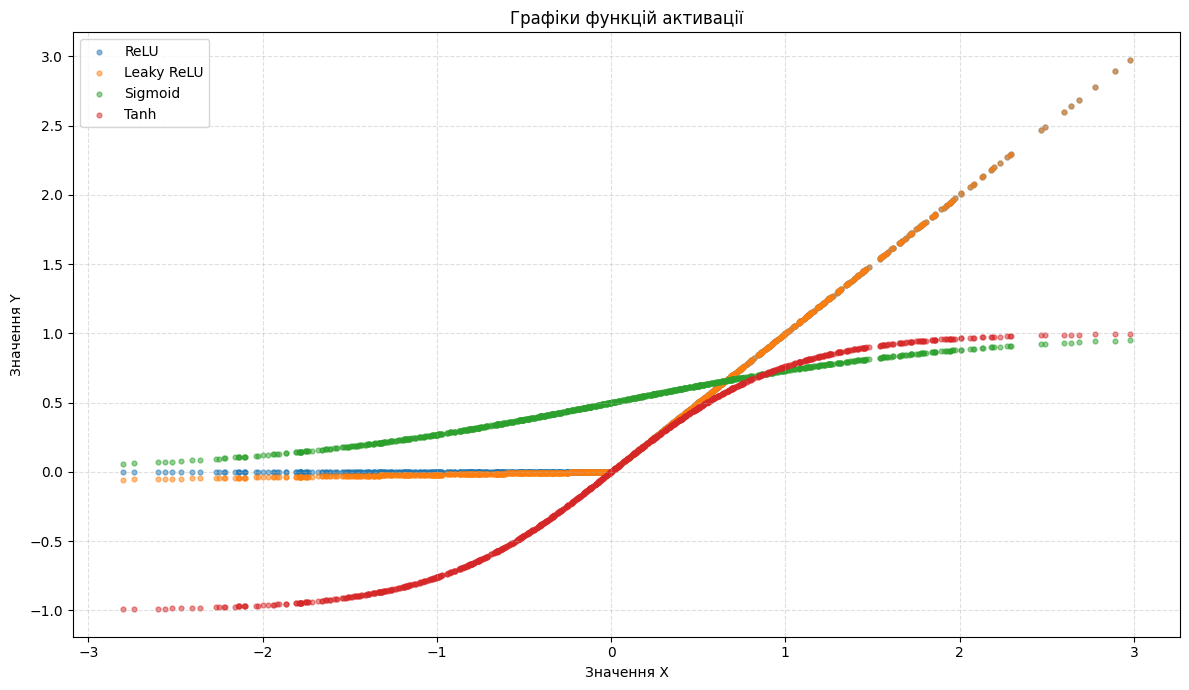

In [2]:
import torch
import matplotlib.pyplot as plt

# Генеруємо 1000 випадкових значень X
x = torch.randn(1000)

# Створюємо функції активації
activations = {
    "ReLU": torch.nn.ReLU(),
    "Leaky ReLU": torch.nn.LeakyReLU(0.02),
    "Sigmoid": torch.nn.Sigmoid(),
    "Tanh": torch.nn.Tanh()
}

# Будуємо графік для кожної функції
plt.figure(figsize=(12, 7))

for name, activation in activations.items():
    y = activation(x)
    plt.scatter(x.numpy(), y.numpy(), s=12, alpha=0.5, label=name)

plt.title("Графіки функцій активації")
plt.xlabel("Значення X")
plt.ylabel("Значення Y")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

##6. Яким чином утворилася така кількість параметрів у нейронній мережі?
Кількість параметрів визначається кількістю ваг між нейронами та зміщень (bias) у кожному шарі. Для мережі з архітектурою 7 → 64 → 32 → 1 розрахунок такий:
- Перший шар: 7 * 64 + 64 = 512.
- Другий шар: 64 * 32 + 32 = 2080.
- Вихідний шар: 32 * 1 + 1 = 33.
Загальна кількість параметрів — 2625. Усі вони налаштовуються під час навчання мережі.
##7. Чи оптимально вибрано кількість епох у пункті 3.5?
200 епох достатньо для навчання моделі, оскільки приблизно після 50–70 епох значення train loss і validation loss зближуються, а покращення сповільнюється. Явних ознак перенавчання немає. Для автоматичного визначення оптимальної тривалості навчання можна застосувати Early Stopping, який зупиняє процес, коли якість на валідаційній вибірці перестає покращуватися.

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [1]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Незнайко Віталій Костянтинович"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#3): Concrete Compressive Strength


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.


In [3]:
from google.colab import drive
import os
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/Lab2"
os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)

Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/Lab2


In [4]:
# Встановлення бібліотеки
!pip install -q datasets

from datasets import load_dataset

# Завантаження датасету
HF_REPO_ID = "foundry-ml/dataset_concrete_compressive_strength"

concrete_dataset = load_dataset(HF_REPO_ID)

# Перегляд інформації про датасет
print(concrete_dataset)

README.md:   0%|          | 0.00/2.52k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 24.6kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1030 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals) '],
        num_rows: 1030
    })
})


In [5]:
import pandas as pd

df = concrete_dataset["train"].to_pandas()

print("Розмір датасету:", df.shape)
display(df.head())


Розмір датасету: (1030, 8)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,360,44.30


In [6]:
# Поділ датасету на вибірки
from sklearn.model_selection import train_test_split

# Спочатку виділяємо 70% для навчання
train_df, remaining_df = train_test_split(
    df,
    test_size=0.3,
    random_state=42,
    shuffle=True
)

# Решту ділимо порівну між validation і test
val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.5,
    random_state=42,
    shuffle=True
)

print(f"Тренувальна вибірка: {train_df.shape}")
print(f"Валідаційна вибірка: {val_df.shape}")
print(f"Тестова вибірка: {test_df.shape}")


Тренувальна вибірка: (721, 8)
Валідаційна вибірка: (154, 8)
Тестова вибірка: (155, 8)


In [7]:
#Загальний огляд (head/info/describe, 1.4).
train_df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
196,194.7,0.0,100.5,165.6,7.5,1006.4,28,25.72
631,325.0,0.0,0.0,184.0,0.0,1063.0,7,17.54
81,318.8,212.5,0.0,155.7,14.3,852.1,3,25.20
526,359.0,19.0,141.0,154.0,10.9,942.0,3,23.64
830,162.0,190.0,148.0,179.0,19.0,838.0,28,33.76


In [8]:
train_df.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,721.000000,721.000000,721.000000,721.000000,721.000000,721.000000,721.000000,721.000000
mean,284.412344,74.972399,52.007490,181.806380,6.126768,973.798474,46.049931,36.152732
std,108.360156,87.717518,63.707622,21.158364,6.046401,78.509319,61.650743,16.803538
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,1.000000,2.330000
25%,192.000000,0.000000,0.000000,165.600000,0.000000,932.000000,14.000000,23.890000
50%,277.000000,22.000000,0.000000,185.700000,6.000000,968.000000,28.000000,35.080000
75%,362.600000,145.000000,117.500000,192.000000,10.100000,1040.000000,56.000000,46.250000
max,540.000000,359.400000,195.000000,247.000000,32.200000,1145.000000,365.000000,82.600000


In [9]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 721 entries, 196 to 860
Data columns (total 8 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              721 non-null    float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  721 non-null    float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             721 non-null    float64
 3   Water  (component 4)(kg in a m^3 mixture)              721 non-null    float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    721 non-null    float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   721 non-null    float64
 6   Age (day)                                              721 non-null    int64  
 7   Concrete compressive strength(MPa, megapascals)        721 non-null    float64
dtypes: float64(7), int64(1)
memory usage: 50.7 KB


In [10]:
train_df.isna().any().any()

np.False_

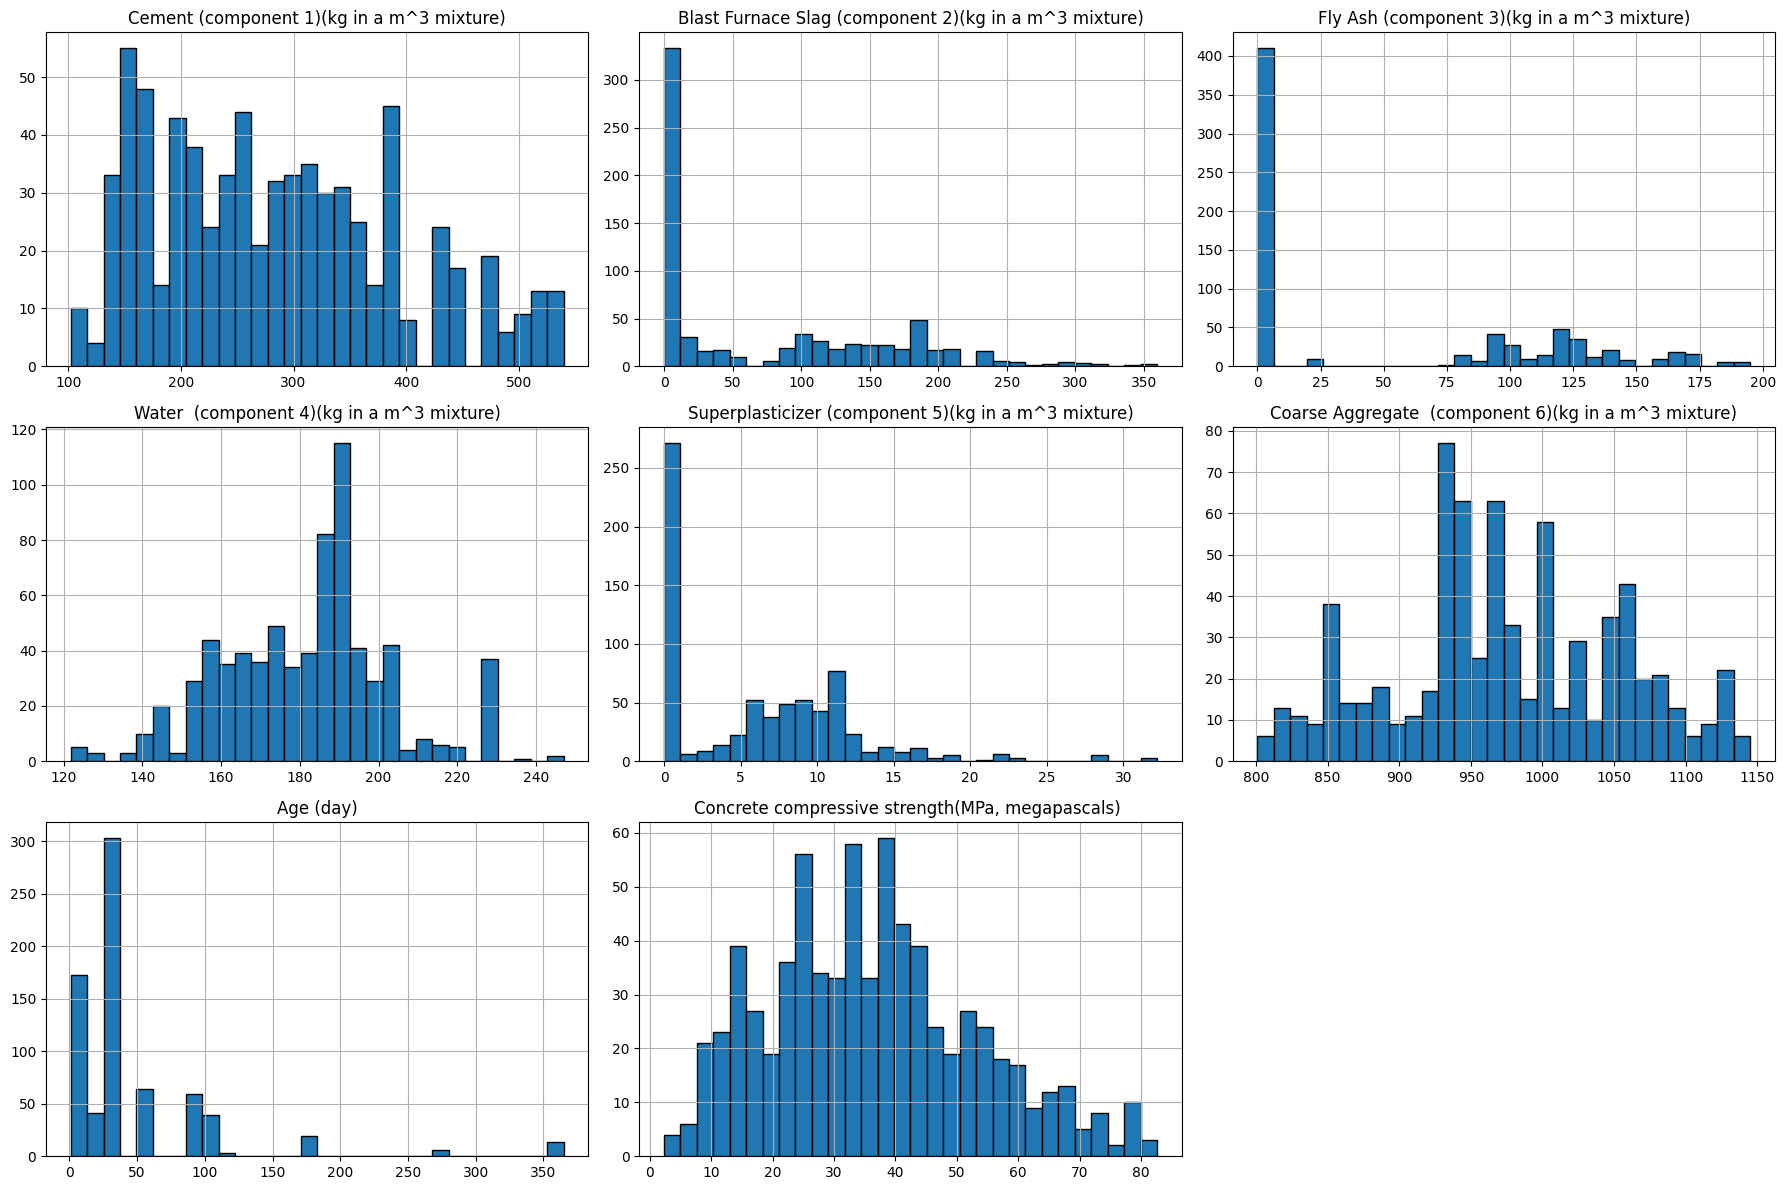

In [11]:
import matplotlib.pyplot as plt

# Побудова гістограм числових ознак
train_df.hist(
    bins=30,
    figsize=(18, 12),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

In [12]:
from scipy.stats import skew

# Перевірка найбільших значень для кожної ознаки
for col in train_df.select_dtypes(include="number").columns:
    print(f"{col} — найбільші значення:")
    print(train_df[col].value_counts().sort_index(ascending=False).head(5))
    print()

# Обчислення асиметрії розподілу
print("Skewness за колонками:")

for col in train_df.select_dtypes(include="number").columns:
    print(f"{col}: {skew(train_df[col].dropna()):.2f}")


Cement (component 1)(kg in a m^3 mixture) — найбільші значення:
Cement (component 1)(kg in a m^3 mixture)
540.0    7
531.3    5
528.0    1
525.0    7
522.0    2
Name: count, dtype: int64

Blast Furnace Slag (component 2)(kg in a m^3 mixture) — найбільші значення:
Blast Furnace Slag (component 2)(kg in a m^3 mixture)
359.4    2
342.1    1
316.1    2
305.3    3
290.2    2
Name: count, dtype: int64

Fly Ash (component 3)(kg in a m^3 mixture) — найбільші значення:
Fly Ash (component 3)(kg in a m^3 mixture)
195.0    3
194.9    1
194.0    1
190.0    1
185.3    1
Name: count, dtype: int64

Water  (component 4)(kg in a m^3 mixture) — найбільші значення:
Water  (component 4)(kg in a m^3 mixture)
247.0     1
246.9     1
237.0     1
228.0    37
221.0     1
Name: count, dtype: int64

Superplasticizer (component 5)(kg in a m^3 mixture) — найбільші значення:
Superplasticizer (component 5)(kg in a m^3 mixture)
32.2    3
28.2    5
23.4    3
22.1    1
22.0    5
Name: count, dtype: int64

Coarse Aggrega

За результатами аналізу більшість числових ознак мають додатну асиметрію. Найбільше вона виражена у Age (day) (3.30) та Superplasticizer (0.95), тоді як Water (0.06) і Coarse Aggregate (-0.02) мають майже симетричні розподіли. У датасеті присутні великі значення віку та компонентів бетонної суміші, які потребують додаткової перевірки на викиди. Загалом перед навчанням моделі доцільно розглянути масштабування ознак.

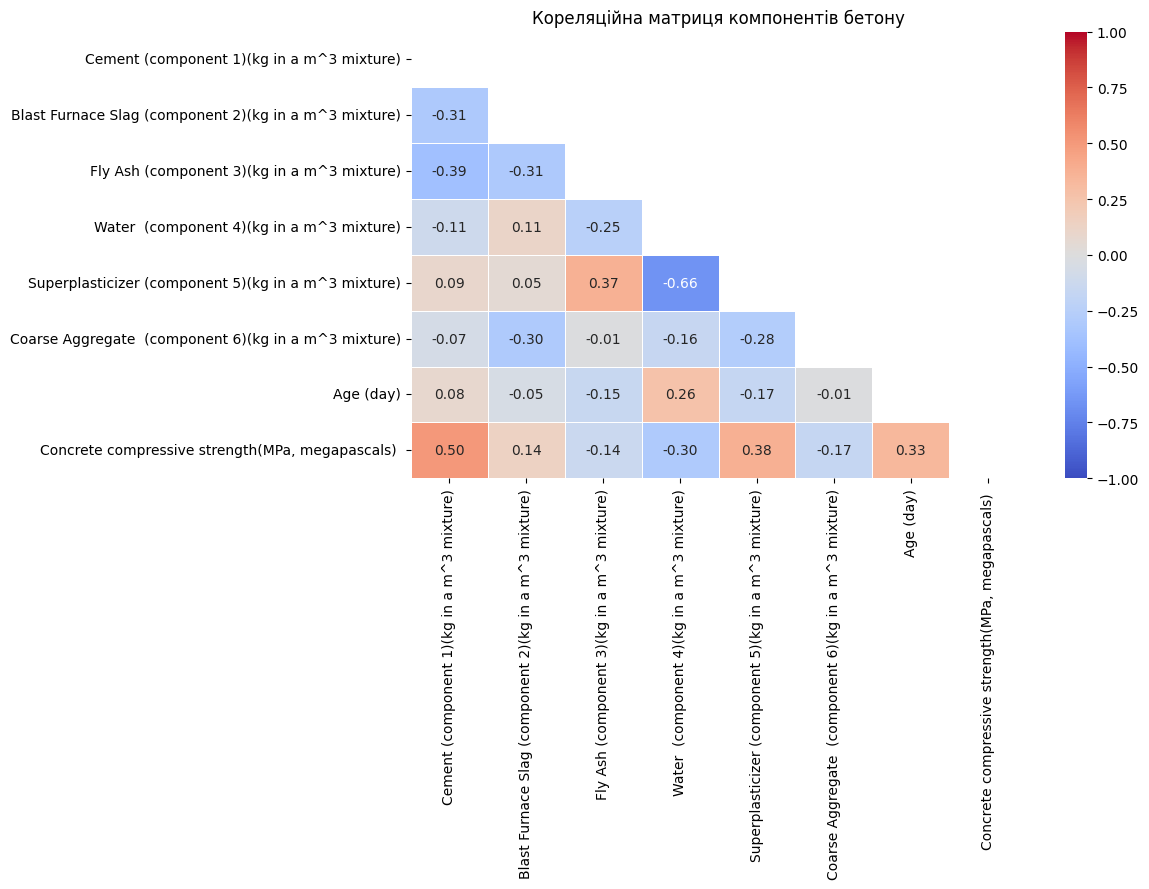

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def corr_mat(df):
    corr = df.corr(numeric_only=True).round(2)

    fig, ax = plt.subplots(figsize=(12, 9))

    mask = np.triu(np.ones_like(corr, dtype=bool))

    sns.heatmap(
        corr,
        mask=mask,
        vmin=-1,
        vmax=1,
        center=0,
        cmap="coolwarm",
        annot=True,
        linewidths=0.5,
        fmt=".2f",
        ax=ax
    )

    ax.set_title("Кореляційна матриця компонентів бетону")
    plt.tight_layout()
    plt.show()

corr_mat(train_df)


Аналіз кореляційної матриці не виявив критичної мультиколінеарності між ознаками, оскільки абсолютні значення коефіцієнтів кореляції не перевищують 0,7. Найсильніший зв'язок спостерігається між вмістом води та суперпластифікатора (r = -0,66), що пояснюється технологічною залежністю: використання суперпластифікатора дає змогу зменшувати кількість води в суміші. Також помітні обернені кореляції між цементом і золою-виносу (r = -0,39), цементом і доменним шлаком (r = -0,31), що пов'язано з частковою заміною цементу мінеральними добавками. Проте всі розглянуті ознаки характеризують різні компоненти та властивості бетонної суміші, тому їх доцільно залишити в наборі даних для подальшого аналізу та побудови моделей.

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

#Масштабування ознак і визначення цільової змінної

In [14]:
# Масштабування ознак і визначення цільової змінної

from sklearn.preprocessing import StandardScaler

target_col = "Concrete compressive strength(MPa, megapascals) "

feature_cols = [
    col for col in train_df.select_dtypes(include="number").columns
    if col != target_col
]

scaler = StandardScaler()

# Навчання scaler лише на тренувальних даних
X_train = scaler.fit_transform(train_df[feature_cols])

# Масштабування валідаційної та тестової вибірок
X_val = scaler.transform(val_df[feature_cols])
X_test = scaler.transform(test_df[feature_cols])

# Цільова змінна — міцність бетону
y_train = train_df[target_col].values
y_val = val_df[target_col].values
y_test = test_df[target_col].values

print("Ознаки:", feature_cols)
print("Форма X_train:", X_train.shape)
print("Форма X_val:", X_val.shape)
print("Форма X_test:", X_test.shape)


Ознаки: ['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Age (day)']
Форма X_train: (721, 7)
Форма X_val: (154, 7)
Форма X_test: (155, 7)


#Перетворення даних у тензори PyTorch

In [15]:
# Перетворення даних у тензори PyTorch

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def to_tensor(X, y):
    X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
    y_tensor = torch.tensor(y, dtype=torch.float32).reshape(-1, 1).to(device)
    return X_tensor, y_tensor

# Перетворення вибірок
x_train_t, y_train_t = to_tensor(X_train, y_train)
x_val_t, y_val_t = to_tensor(X_val, y_val)
x_test_t, y_test_t = to_tensor(X_test, y_test)

# Перевірка розмірів тензорів
print("Пристрій:", device)
print("X_train:", x_train_t.shape)
print("y_train:", y_train_t.shape)
print("X_val:", x_val_t.shape)
print("y_val:", y_val_t.shape)
print("X_test:", x_test_t.shape)
print("y_test:", y_test_t.shape)


Пристрій: cpu
X_train: torch.Size([721, 7])
y_train: torch.Size([721, 1])
X_val: torch.Size([154, 7])
y_val: torch.Size([154, 1])
X_test: torch.Size([155, 7])
y_test: torch.Size([155, 1])


#Тренування nn.Linear

In [16]:
import os
from torch.utils.tensorboard import SummaryWriter

N_EPOCHS = 50

# Кількість вхідних ознак
n_features = x_train_t.shape[1]

# Створення лінійної моделі
linear_model = torch.nn.Linear(
    in_features=n_features,
    out_features=1
).to(device)

# Налаштування оптимізатора та функції втрат
optimizer = torch.optim.SGD(
    linear_model.parameters(),
    lr=0.1
)

loss_fn = torch.nn.MSELoss()

# Запис результатів у TensorBoard
writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "concrete_linear")
)

train_losses, val_losses = [], []

for epoch in range(N_EPOCHS):
    # Навчання моделі
    linear_model.train()
    optimizer.zero_grad()

    y_pred = linear_model(x_train_t)
    loss = loss_fn(y_pred, y_train_t)

    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    # Перевірка на валідаційній вибірці
    linear_model.eval()

    with torch.no_grad():
        val_loss = loss_fn(
            linear_model(x_val_t),
            y_val_t
        ).item()

    val_losses.append(val_loss)

    # Збереження метрик
    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 5 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"Епоха {epoch + 1:3d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

writer.close()

Епоха   1 | Train Loss: 1587.6737 | Val Loss: 963.3138
Епоха   6 | Train Loss: 277.7947 | Val Loss: 225.0744
Епоха  11 | Train Loss: 136.7676 | Val Loss: 145.3868
Епоха  16 | Train Loss: 118.3411 | Val Loss: 133.9740
Епоха  21 | Train Loss: 114.1611 | Val Loss: 130.0071
Епоха  26 | Train Loss: 112.2456 | Val Loss: 127.3299
Епоха  31 | Train Loss: 111.0485 | Val Loss: 125.2803
Епоха  36 | Train Loss: 110.2455 | Val Loss: 123.6990
Епоха  41 | Train Loss: 109.6988 | Val Loss: 122.4771
Епоха  46 | Train Loss: 109.3250 | Val Loss: 121.5278
Епоха  50 | Train Loss: 109.1126 | Val Loss: 120.9195


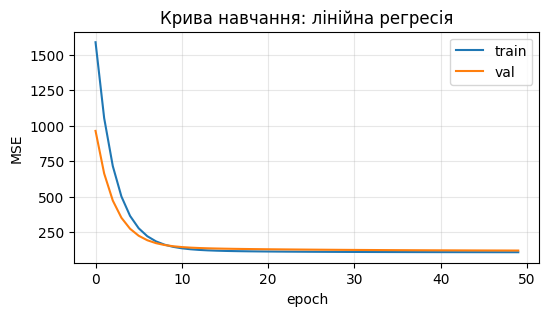

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))

plt.plot(train_losses, label="train")
plt.plot(val_losses, label="val")

plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("Крива навчання: лінійна регресія")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

#Метрики на test


In [19]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Переводимо модель у режим оцінювання
linear_model.eval()

with torch.no_grad():
    y_test_pred = linear_model(x_test_t).cpu().numpy().flatten()

# Бейзлайн: прогнозуємо середнє значення цільової ознаки train
baseline_pred = np.full_like(y_test, y_train.mean())


def report(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "Модель": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R²": r2
    }


metrics_df = pd.DataFrame([
    report(y_test, baseline_pred, "Бейзлайн"),
    report(y_test, y_test_pred, "Лінійна регресія")
])

metrics_df = metrics_df.round(4)
display(metrics_df)

,Модель,MSE,RMSE,MAE,R²
0,Бейзлайн,250.2802,15.8202,12.8782,-0.0000
1,Лінійна регресія,99.5862,9.9793,7.9974,0.6021


Лінійна регресія показала кращі результати порівняно з бейзлайном. Значення MSE зменшилося з 250.2802 до 99.5862, а RMSE — з 15.8202 до 9.9793. Середня абсолютна похибка MAE становить 7.9974 МПа. Коефіцієнт детермінації \(R^2 = 0.6021\) свідчить, що модель пояснює приблизно 60,21% варіації міцності бетону на стиск. Отже, лінійна регресія забезпечує точніші прогнози, ніж передбачення середнього значення цільової ознаки, проте її точність можна спробувати покращити за допомогою складніших моделей.

In [20]:
import os
import torch

# Каталог для моделей
MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

# Шлях до файлу лінійної моделі
MODEL_PATH = os.path.join(MODELS_DIR, "linear.pt")

# Зберігаємо параметри навченої моделі
torch.save(linear_model.state_dict(), MODEL_PATH)

print("Модель збережено:", MODEL_PATH)
print("Каталог для наступних моделей:", MODELS_DIR)


Модель збережено: /content/drive/MyDrive/ai_systems/Lab2/models/linear.pt
Каталог для наступних моделей: /content/drive/MyDrive/ai_systems/Lab2/models


#Інтерпретація ваг

In [21]:
import pandas as pd

weights = linear_model.weight.detach().cpu().numpy().flatten()

weight_df = pd.DataFrame({
    "Ознака": feature_cols,
    "Вага": weights
})

weight_df["abs_weight"] = weight_df["Вага"].abs()

weight_df = weight_df.sort_values(
    "abs_weight",
    ascending=False
).drop(columns="abs_weight")

display(weight_df.round(4))


,Ознака,Вага
0,Cement (component 1)(kg in a m^3 mixture),10.0252
6,Age (day),6.8512
1,Blast Furnace Slag (component 2)(kg in a m^3 m...,6.7666
3,Water (component 4)(kg in a m^3 mixture),-3.9146
4,Superplasticizer (component 5)(kg in a m^3 mix...,2.8776
2,Fly Ash (component 3)(kg in a m^3 mixture),2.5107
5,Coarse Aggregate (component 6)(kg in a m^3 mi...,0.0377


Найбільшу додатну вагу в моделі має цемент (10.0252), за ним ідуть вік бетону (6.8512) та доменний шлак (6.7666). Це означає, що в межах навченої моделі ці ознаки мають найбільший позитивний вплив на прогнозовану міцність. Вода має від’ємну вагу (-3.9146), тоді як вага крупного заповнювача майже дорівнює нулю (0.0377), тобто його внесок у лінійний прогноз моделі є незначним. Оскільки вхідні ознаки стандартизовані, їхні ваги можна порівнювати за абсолютною величиною.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

#nn_v1

In [22]:
nn_v1 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

print(nn_v1)

print(
    "Кількість параметрів NN v1:",
    sum(p.numel() for p in nn_v1.parameters())
)

print(
    "Кількість параметрів лінійної регресії:",
    sum(p.numel() for p in linear_model.parameters())
)

Sequential(
  (0): Linear(in_features=7, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN v1: 2625
Кількість параметрів лінійної регресії: 8


In [23]:
# Тренування нейромережі — архітектура №1
N_EPOCHS = 200

optimizer = torch.optim.Adam(nn_v1.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()

writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "concrete_nn_v1")
)

nn_v1_train_losses = []
nn_v1_val_losses = []

for epoch in range(N_EPOCHS):
    # Навчання
    nn_v1.train()

    optimizer.zero_grad()
    y_pred = nn_v1(x_train_t)
    loss = loss_fn(y_pred, y_train_t)

    loss.backward()
    optimizer.step()

    nn_v1_train_losses.append(loss.item())

    # Валідація
    nn_v1.eval()

    with torch.no_grad():
        val_loss = loss_fn(
            nn_v1(x_val_t), y_val_t
        ).item()

    nn_v1_val_losses.append(val_loss)

    # Логування у TensorBoard
    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"Епоха {epoch + 1:3d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

writer.close()

Епоха   1 | Train Loss: 1584.4851 | Val Loss: 1415.1844
Епоха  11 | Train Loss: 1142.3127 | Val Loss: 950.7133
Епоха  21 | Train Loss: 238.3188 | Val Loss: 241.8970
Епоха  31 | Train Loss: 232.7216 | Val Loss: 222.7665
Епоха  41 | Train Loss: 203.4198 | Val Loss: 205.8650
Епоха  51 | Train Loss: 159.6505 | Val Loss: 177.4917
Епоха  61 | Train Loss: 145.9924 | Val Loss: 161.3582
Епоха  71 | Train Loss: 138.2102 | Val Loss: 153.2271
Епоха  81 | Train Loss: 132.0280 | Val Loss: 148.4117
Епоха  91 | Train Loss: 126.9819 | Val Loss: 143.7681
Епоха 101 | Train Loss: 122.7868 | Val Loss: 139.4236
Епоха 111 | Train Loss: 119.1814 | Val Loss: 135.6967
Епоха 121 | Train Loss: 115.9347 | Val Loss: 132.1760
Епоха 131 | Train Loss: 113.1875 | Val Loss: 129.2631
Епоха 141 | Train Loss: 111.0739 | Val Loss: 126.9179
Епоха 151 | Train Loss: 109.3606 | Val Loss: 125.0889
Епоха 161 | Train Loss: 107.7277 | Val Loss: 122.9457
Епоха 171 | Train Loss: 105.9313 | Val Loss: 120.5150
Епоха 181 | Train Loss: 1

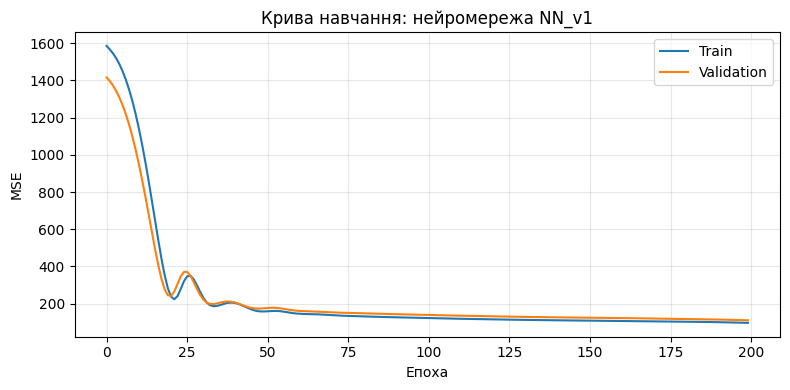

In [24]:
plt.figure(figsize=(8, 4))
plt.plot(nn_v1_train_losses, label="Train")
plt.plot(nn_v1_val_losses, label="Validation")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Крива навчання: нейромережа NN_v1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Прогноз нейромережі
nn_v1.eval()

with torch.no_grad():
    y_nn_v1_pred = nn_v1(x_test_t).cpu().numpy().flatten()


def calculate_metrics(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "Модель": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R²": r2
    }


results = [
    calculate_metrics(y_test, baseline_pred, "Бейзлайн"),
    calculate_metrics(y_test, y_test_pred, "Лінійна регресія"),
    calculate_metrics(y_test, y_nn_v1_pred, "Нейромережа NN_v1")
]

metrics_df = pd.DataFrame(results)
display(metrics_df.round(4))

,Модель,MSE,RMSE,MAE,R²
0,Бейзлайн,250.2802,15.8202,12.8782,-0.0000
1,Лінійна регресія,99.5862,9.9793,7.9974,0.6021
2,Нейромережа NN_v1,90.9764,9.5382,7.6904,0.6365


Нейромережа NN_v1 показала найкращий результат серед трьох моделей. Порівняно з лінійною регресією, значення MSE зменшилося з 99.5862 до 90.9764, а MAE — з 7.9974 до 7.6904 МПа. Коефіцієнт детермінації зріс із 0.6021 до 0.6365, тобто модель пояснює 63.65% варіації міцності бетону на стиск. Отже, нейромережа з двома прихованими шарами дещо точніша за лінійну регресію на тестовій вибірці, хоча покращення є помірним.



In [26]:
import os
import torch

# Каталог для моделей
MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

# Шлях до файлу нейромережі
MODEL_PATH = os.path.join(MODELS_DIR, "nn_v1.pt")

# Зберігаємо параметри навченої нейромережі
torch.save(nn_v1.state_dict(), MODEL_PATH)

print("Нейромережу збережено:", MODEL_PATH)
print("Каталог для наступних моделей:", MODELS_DIR)

Нейромережу збережено: /content/drive/MyDrive/ai_systems/Lab2/models/nn_v1.pt
Каталог для наступних моделей: /content/drive/MyDrive/ai_systems/Lab2/models


#nn_v2

In [27]:
# Нейромережа, архітектура №2
nn_v2 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

print(nn_v2)

print(
    "Кількість параметрів NN v2:",
    sum(p.numel() for p in nn_v2.parameters())
)

Sequential(
  (0): Linear(in_features=7, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): ReLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN v2: 11393


In [28]:
# Тренування нейромережі — архітектура №2
N_EPOCHS = 200

optimizer_v2 = torch.optim.Adam(nn_v2.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()

writer_v2 = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "concrete_nn_v2_deeper")
)

nn_v2_train_losses = []
nn_v2_val_losses = []

for epoch in range(N_EPOCHS):
    # Навчання
    nn_v2.train()

    optimizer_v2.zero_grad()
    y_pred = nn_v2(x_train_t)
    loss = loss_fn(y_pred, y_train_t)

    loss.backward()
    optimizer_v2.step()

    nn_v2_train_losses.append(loss.item())

    # Валідація
    nn_v2.eval()

    with torch.no_grad():
        val_loss = loss_fn(
            nn_v2(x_val_t), y_val_t
        ).item()

    nn_v2_val_losses.append(val_loss)

    # Логування у TensorBoard
    writer_v2.add_scalar("Loss/train", loss.item(), epoch)
    writer_v2.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"Епоха {epoch + 1:3d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

writer_v2.close()

Епоха   1 | Train Loss: 1603.1877 | Val Loss: 1424.1021
Епоха  11 | Train Loss: 286.9413 | Val Loss: 395.5327
Епоха  21 | Train Loss: 306.9088 | Val Loss: 312.6783
Епоха  31 | Train Loss: 221.5358 | Val Loss: 233.5223
Епоха  41 | Train Loss: 176.5247 | Val Loss: 187.1449
Епоха  51 | Train Loss: 146.9418 | Val Loss: 162.0872
Епоха  61 | Train Loss: 133.4728 | Val Loss: 151.6597
Епоха  71 | Train Loss: 122.1948 | Val Loss: 141.3320
Епоха  81 | Train Loss: 110.2279 | Val Loss: 128.2624
Епоха  91 | Train Loss: 95.0725 | Val Loss: 113.1635
Епоха 101 | Train Loss: 74.6805 | Val Loss: 91.7997
Епоха 111 | Train Loss: 54.7728 | Val Loss: 65.6032
Епоха 121 | Train Loss: 44.1181 | Val Loss: 52.1889
Епоха 131 | Train Loss: 37.8562 | Val Loss: 49.9699
Епоха 141 | Train Loss: 33.0219 | Val Loss: 44.5600
Епоха 151 | Train Loss: 29.3549 | Val Loss: 42.0188
Епоха 161 | Train Loss: 26.5924 | Val Loss: 39.3155
Епоха 171 | Train Loss: 24.3651 | Val Loss: 38.4880
Епоха 181 | Train Loss: 22.3867 | Val Loss:

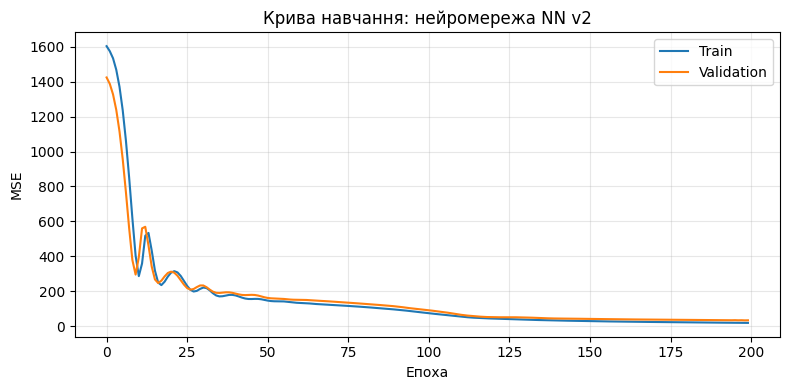

In [29]:
plt.figure(figsize=(8, 4))
plt.plot(nn_v2_train_losses, label="Train")
plt.plot(nn_v2_val_losses, label="Validation")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Крива навчання: нейромережа NN v2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Прогнози нейромереж
nn_v1.eval()
nn_v2.eval()

with torch.no_grad():
    y_nn_v1_pred = nn_v1(x_test_t).cpu().numpy().flatten()
    y_nn_v2_pred = nn_v2(x_test_t).cpu().numpy().flatten()


def calculate_metrics(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "Модель": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R²": r2
    }


results = [
    calculate_metrics(y_test, baseline_pred, "Бейзлайн"),
    calculate_metrics(y_test, y_test_pred, "Лінійна регресія"),
    calculate_metrics(y_test, y_nn_v1_pred, "Нейромережа NN v1"),
    calculate_metrics(y_test, y_nn_v2_pred, "Нейромережа NN v2")
]

metrics_df = pd.DataFrame(results)
display(metrics_df.round(4))

,Модель,MSE,RMSE,MAE,R²
0,Бейзлайн,250.2802,15.8202,12.8782,-0.0000
1,Лінійна регресія,99.5862,9.9793,7.9974,0.6021
2,Нейромережа NN v1,90.9764,9.5382,7.6904,0.6365
3,Нейромережа NN v2,40.2105,6.3412,4.9736,0.8393


Найкращі результати показала нейромережа NN_v2 із трьома прихованими шарами. Її MSE становить 40.2105, RMSE — 6.3412 МПа, а MAE — 4.9736 МПа. Коефіцієнт детермінації \(R^2 = 0.8393\) свідчить, що модель пояснює 83.93% варіації міцності бетону на стиск.

In [31]:
import os
import torch

# Каталог для моделей
MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

# Шлях до файлу нейромережі
MODEL_PATH = os.path.join(MODELS_DIR, "nn_v2.pt")

# Зберігаємо параметри навченої нейромережі
torch.save(nn_v2.state_dict(), MODEL_PATH)

print("Нейромережу збережено:", MODEL_PATH)
print("Каталог для наступних моделей:", MODELS_DIR)

Нейромережу збережено: /content/drive/MyDrive/ai_systems/Lab2/models/nn_v2.pt
Каталог для наступних моделей: /content/drive/MyDrive/ai_systems/Lab2/models


### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

#Експеримент 1. Зменшення learning rate

In [32]:
import os
from torch.utils.tensorboard import SummaryWriter

torch.manual_seed(42)

nn_v2_lr = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

N_EPOCHS = 200
optimizer = torch.optim.Adam(nn_v2_lr.parameters(), lr=0.001)
loss_fn = torch.nn.MSELoss()

writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "nn_v2_lr_001"))
lr_train_losses, lr_val_losses = [], []

for epoch in range(N_EPOCHS):
    nn_v2_lr.train()
    optimizer.zero_grad()

    y_pred = nn_v2_lr(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()

    lr_train_losses.append(loss.item())

    nn_v2_lr.eval()
    with torch.no_grad():
        val_loss = loss_fn(nn_v2_lr(x_val_t), y_val_t).item()

    lr_val_losses.append(val_loss)
    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"Епоха {epoch + 1:3d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

writer.close()


Епоха   1 | Train Loss: 1588.1777 | Val Loss: 1434.2046
Епоха  11 | Train Loss: 1560.6652 | Val Loss: 1406.8536
Епоха  21 | Train Loss: 1491.9630 | Val Loss: 1336.4930
Епоха  31 | Train Loss: 1334.5065 | Val Loss: 1180.1958
Епоха  41 | Train Loss: 1046.5240 | Val Loss: 903.4464
Епоха  51 | Train Loss: 643.6566 | Val Loss: 538.0134
Епоха  61 | Train Loss: 316.8286 | Val Loss: 287.5004
Епоха  71 | Train Loss: 268.7439 | Val Loss: 281.5728
Епоха  81 | Train Loss: 236.7262 | Val Loss: 242.2391
Епоха  91 | Train Loss: 216.8441 | Val Loss: 221.7230
Епоха 101 | Train Loss: 207.5598 | Val Loss: 213.1932
Епоха 111 | Train Loss: 197.5956 | Val Loss: 205.9427
Епоха 121 | Train Loss: 190.3392 | Val Loss: 199.5627
Епоха 131 | Train Loss: 183.5897 | Val Loss: 193.2181
Епоха 141 | Train Loss: 177.6927 | Val Loss: 188.0466
Епоха 151 | Train Loss: 172.3147 | Val Loss: 183.4838
Епоха 161 | Train Loss: 167.4601 | Val Loss: 179.1224
Епоха 171 | Train Loss: 162.9670 | Val Loss: 174.8981
Епоха 181 | Train L

#Експеримент 2. Заміна оптимізатора Adam на SGD

In [34]:
torch.manual_seed(42)

nn_v2_sgd = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

N_EPOCHS = 200
optimizer = torch.optim.SGD(nn_v2_sgd.parameters(), lr=0.001)
loss_fn = torch.nn.MSELoss()

writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "nn_v2_sgd"))
sgd_train_losses, sgd_val_losses = [], []

for epoch in range(N_EPOCHS):
    nn_v2_sgd.train()
    optimizer.zero_grad()

    y_pred = nn_v2_sgd(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()

    sgd_train_losses.append(loss.item())

    nn_v2_sgd.eval()
    with torch.no_grad():
        val_loss = loss_fn(nn_v2_sgd(x_val_t), y_val_t).item()

    sgd_val_losses.append(val_loss)
    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"Епоха {epoch + 1:3d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

writer.close()

Епоха   1 | Train Loss: 1588.1777 | Val Loss: 1429.1173
Епоха  11 | Train Loss: 1487.5330 | Val Loss: 1320.2335
Епоха  21 | Train Loss: 202.4635 | Val Loss: 207.0941
Епоха  31 | Train Loss: 156.7557 | Val Loss: 169.8487
Епоха  41 | Train Loss: 133.6362 | Val Loss: 147.2516
Епоха  51 | Train Loss: 115.3446 | Val Loss: 128.9212
Епоха  61 | Train Loss: 98.7682 | Val Loss: 112.4545
Епоха  71 | Train Loss: 84.1140 | Val Loss: 97.9368
Епоха  81 | Train Loss: 71.5826 | Val Loss: 85.4543
Епоха  91 | Train Loss: 65.8880 | Val Loss: 82.3466
Епоха 101 | Train Loss: 234.5834 | Val Loss: 144.7588
Епоха 111 | Train Loss: 167.3915 | Val Loss: 121.4805
Епоха 121 | Train Loss: 148.3680 | Val Loss: 111.8573
Епоха 131 | Train Loss: 137.4606 | Val Loss: 104.8690
Епоха 141 | Train Loss: 129.3310 | Val Loss: 99.2861
Епоха 151 | Train Loss: 122.5632 | Val Loss: 94.5654
Епоха 161 | Train Loss: 116.5094 | Val Loss: 90.2676
Епоха 171 | Train Loss: 110.5014 | Val Loss: 86.2703
Епоха 181 | Train Loss: 105.5752 | 

#Експеримент 3. Збільшення кількості епох

In [35]:
torch.manual_seed(42)

nn_v2_epochs = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

N_EPOCHS = 300
optimizer = torch.optim.Adam(nn_v2_epochs.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()

writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "nn_v2_300_epochs"))
epochs_train_losses, epochs_val_losses = [], []

for epoch in range(N_EPOCHS):
    nn_v2_epochs.train()
    optimizer.zero_grad()

    y_pred = nn_v2_epochs(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()

    epochs_train_losses.append(loss.item())

    nn_v2_epochs.eval()
    with torch.no_grad():
        val_loss = loss_fn(nn_v2_epochs(x_val_t), y_val_t).item()

    epochs_val_losses.append(val_loss)
    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"Епоха {epoch + 1:3d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

writer.close()

Епоха   1 | Train Loss: 1588.1777 | Val Loss: 1414.3573
Епоха  11 | Train Loss: 320.1398 | Val Loss: 502.3659
Епоха  21 | Train Loss: 303.7237 | Val Loss: 291.9607
Епоха  31 | Train Loss: 201.2542 | Val Loss: 197.2608
Епоха  41 | Train Loss: 159.4113 | Val Loss: 167.0312
Епоха  51 | Train Loss: 139.3543 | Val Loss: 152.4508
Епоха  61 | Train Loss: 129.7034 | Val Loss: 142.5588
Епоха  71 | Train Loss: 118.8589 | Val Loss: 134.2342
Епоха  81 | Train Loss: 109.3730 | Val Loss: 123.8623
Епоха  91 | Train Loss: 97.6610 | Val Loss: 112.1367
Епоха 101 | Train Loss: 82.6391 | Val Loss: 95.8830
Епоха 111 | Train Loss: 64.4349 | Val Loss: 75.6886
Епоха 121 | Train Loss: 49.9240 | Val Loss: 59.2224
Епоха 131 | Train Loss: 42.3064 | Val Loss: 50.0670
Епоха 141 | Train Loss: 37.3066 | Val Loss: 45.1378
Епоха 151 | Train Loss: 33.3602 | Val Loss: 41.8747
Епоха 161 | Train Loss: 30.3022 | Val Loss: 39.6549
Епоха 171 | Train Loss: 28.0697 | Val Loss: 37.8181
Епоха 181 | Train Loss: 26.2096 | Val Loss:

#Порівняння результатів


In [36]:
models = [
    (nn_v2, "NN v2 — базова"),
    (nn_v2_lr, "NN v2 — lr=0.001"),
    (nn_v2_sgd, "NN v2 — SGD"),
    (nn_v2_epochs, "NN v2 — 300 епох"),
]

results = []

for model, name in models:
    model.eval()
    with torch.no_grad():
        predictions = model(x_test_t).cpu().numpy().flatten()

    results.append(calculate_metrics(y_test, predictions, name))

tuning_df = pd.DataFrame(results)
tuning_df = tuning_df.sort_values("MSE").reset_index(drop=True)

display(tuning_df.round(4))

,Модель,MSE,RMSE,MAE,R²
0,NN v2 — 300 епох,38.9684,6.2425,4.5695,0.8443
1,NN v2 — базова,40.2105,6.3412,4.9736,0.8393
2,NN v2 — SGD,111.9999,10.5830,8.3834,0.5525
3,NN v2 — lr=0.001,133.0875,11.5364,9.4008,0.4682


Найкращий результат серед усіх перевірених моделей показала **NN v2 із 300 епохами навчання**. Її MSE становив 38.9684, RMSE — 6.2425, MAE — 4.5695, а коефіцієнт детермінації \(R^2\) — 0.8443. Порівняно з базовою NN v2, значення MSE зменшилося приблизно на 3.1%, а \(R^2\) зріс із 0.8393 до 0.8443. Отже, збільшення кількості епох дало невелике, але позитивне покращення.

**Нейромережа виправдала себе порівняно з лінійною регресією.** Лінійна регресія показала MSE = 99.5862 та \(R^2 = 0.6021\), тоді як найкраща нейромережа досягла MSE = 38.9684 та \(R^2 = 0.8443\). Таким чином, MSE зменшився приблизно на 60.9%, а \(R^2\) зріс на 0.2422. Це свідчить про те, що нейромережа краще описує залежності між характеристиками бетонної суміші та її міцністю на стиск.

Найбільший ефект серед досліджених змін дала **зміна архітектури**: перехід від NN v1 до глибшої NN v2 зменшив MSE із 90.9764 до 40.2105, тобто приблизно на 55.8%. Натомість збільшення кількості епох із 200 до 300 дало лише незначне покращення. Зменшення швидкості навчання до 0.001 і заміна Adam на SGD погіршили результати: MSE зріс до 133.0875 та 111.9999 відповідно.

Отже, найкращою серед перевірених конфігурацій стала **NN v2 з оптимізатором Adam, швидкістю навчання 0.01 і 300 епохами**. Експерименти показали, що для цього датасету вибір архітектури мав більший вплив на якість прогнозування, ніж перевірені зміни гіперпараметрів.


In [40]:
import os
import torch

MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

models_to_save = {
    "nn_v2_lr001.pt": nn_v2_lr,
    "nn_v2_sgd.pt": nn_v2_sgd,
    "nn_v2_300_epochs.pt": nn_v2_epochs,
}

for filename, model in models_to_save.items():
    path = os.path.join(MODELS_DIR, filename)
    torch.save(model.state_dict(), path)
    print(f"Збережено: {path}")


Збережено: /content/drive/MyDrive/ai_systems/Lab2/models/nn_v2_lr001.pt
Збережено: /content/drive/MyDrive/ai_systems/Lab2/models/nn_v2_sgd.pt
Збережено: /content/drive/MyDrive/ai_systems/Lab2/models/nn_v2_300_epochs.pt


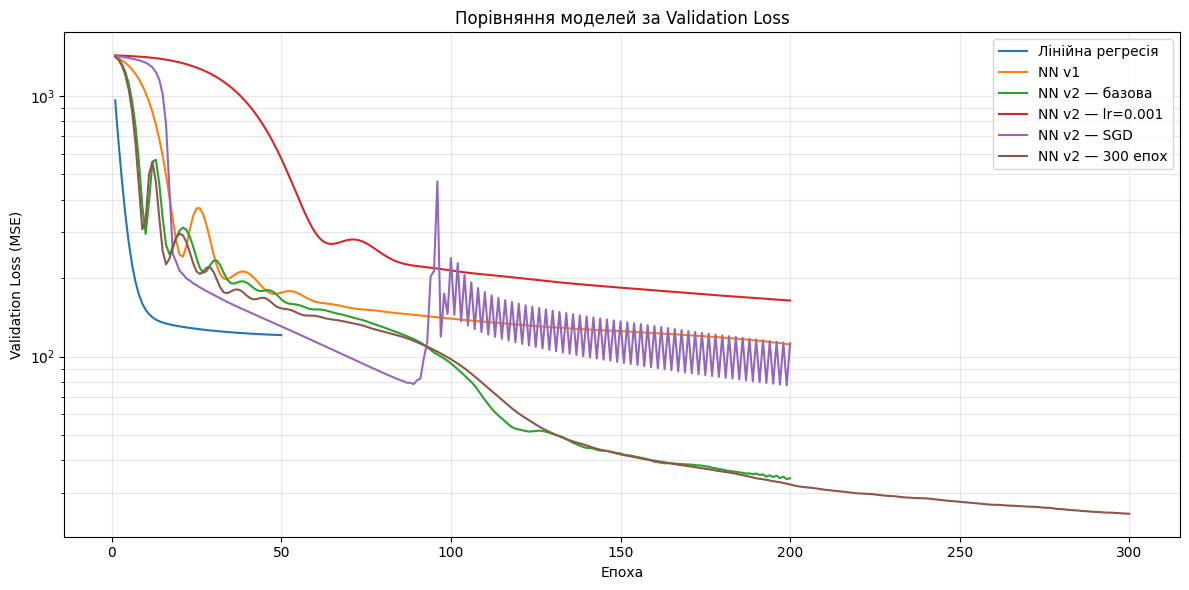

In [37]:
import matplotlib.pyplot as plt

loss_curves = {
    "Лінійна регресія": val_losses,
    "NN v1": nn_v1_val_losses,
    "NN v2 — базова": nn_v2_val_losses,
    "NN v2 — lr=0.001": lr_val_losses,
    "NN v2 — SGD": sgd_val_losses,
    "NN v2 — 300 епох": epochs_val_losses,
}

plt.figure(figsize=(12, 6))

for name, losses in loss_curves.items():
    plt.plot(range(1, len(losses) + 1), losses, label=name)

plt.xlabel("Епоха")
plt.ylabel("Validation Loss (MSE)")
plt.title("Порівняння моделей за Validation Loss")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()



In [38]:
import os
import numpy as np
import pandas as pd
import torch
from google.colab import drive
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Підключення Google Drive
drive.mount("/content/drive")

# Директорія лабораторної роботи
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/Lab2"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Моделі для порівняння
models = {
    "Бейзлайн": None,
    "Лінійна регресія": linear_model,
    "Нейромережа NN v1": nn_v1,
    "Нейромережа NN v2": nn_v2,
    "NN v2 — lr=0.001": nn_v2_lr,
    "NN v2 — SGD": nn_v2_sgd,
    "NN v2 — 300 епох": nn_v2_epochs,
}

results = []

# Розрахунок метрик на тестовій вибірці
for name, model in models.items():
    if model is None:
        predictions = baseline_pred
    else:
        model.eval()
        with torch.no_grad():
            predictions = model(x_test_t).cpu().numpy().flatten()

    mse = mean_squared_error(y_test, predictions)

    results.append({
        "Модель": name,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_test, predictions),
        "R²": r2_score(y_test, predictions),
    })

# Створення таблиці та сортування за MSE
metrics_df = pd.DataFrame(results)
metrics_df = metrics_df.sort_values("MSE").reset_index(drop=True)

display(metrics_df.round(4))

# Збереження результатів у Google Drive
CSV_PATH = os.path.join(ARTIFACT_DIR, "results.csv")
metrics_df.to_csv(CSV_PATH, index=False, encoding="utf-8-sig")

# Перевірка збереження
print("\nРезультати збережено:", CSV_PATH)
print("Файл існує:", os.path.exists(CSV_PATH))
print("Розмір файлу:", os.path.getsize(CSV_PATH), "байт")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Модель,MSE,RMSE,MAE,R²
0,NN v2 — 300 епох,38.9684,6.2425,4.5695,0.8443
1,Нейромережа NN v2,40.2105,6.3412,4.9736,0.8393
2,Нейромережа NN v1,90.9764,9.5382,7.6904,0.6365
3,Лінійна регресія,99.5862,9.9793,7.9974,0.6021
4,NN v2 — SGD,111.9999,10.5830,8.3834,0.5525
5,NN v2 — lr=0.001,133.0875,11.5364,9.4008,0.4682
6,Бейзлайн,250.2802,15.8202,12.8782,-0.0000



Результати збережено: /content/drive/MyDrive/ai_systems/Lab2/results.csv
Файл існує: True
Розмір файлу: 719 байт


---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [39]:
!pip install -q gradio

import gradio as gr
import numpy as np
import pandas as pd
import torch

# Моделі для порівняння
models = {
    "Лінійна регресія": linear_model,
    "NN v1": nn_v1,
    "NN v2 — базова": nn_v2,
    "NN v2 — lr=0.001": nn_v2_lr,
    "NN v2 — SGD": nn_v2_sgd,
    "NN v2 — 300 епох": nn_v2_epochs,
}

# Діапазони ознак: мінімум, максимум, початкове значення
input_ranges = {
    "Cement (component 1)(kg in a m^3 mixture)": (102, 540, 300),
    "Blast Furnace Slag (component 2)(kg in a m^3 mixture)": (0, 360, 100),
    "Fly Ash (component 3)(kg in a m^3 mixture)": (0, 200, 50),
    "Water  (component 4)(kg in a m^3 mixture)": (120, 250, 180),
    "Superplasticizer (component 5)(kg in a m^3 mixture)": (0, 32, 5),
    "Coarse Aggregate  (component 6)(kg in a m^3 mixture)": (800, 1150, 950),
    "Age (day)": (1, 365, 28),
}

def predict_strength(*values):
    # Формування рядка з ознаками у потрібному порядку
    input_data = pd.DataFrame([values], columns=feature_cols)

    # Масштабування ознак за параметрами навчальної вибірки
    input_scaled = scaler.transform(input_data)

    x = torch.tensor(
        input_scaled,
        dtype=torch.float32
    ).to(device)

    predictions = {}

    # Прогнозування нейромережами та лінійною моделлю
    for name, model in models.items():
        model.eval()
        with torch.no_grad():
            prediction = model(x).cpu().numpy().item()

        predictions[name] = round(float(prediction), 2)

    # Бейзлайн прогнозує середнє значення цільової змінної
    predictions["Бейзлайн"] = round(float(y_train.mean()), 2)

    results = pd.DataFrame([
        {"Модель": name, "Прогноз міцності (MPa)": value}
        for name, value in predictions.items()
    ])

    return results.sort_values(
        "Прогноз міцності (MPa)",
        ascending=False
    ).reset_index(drop=True)

# Створення полів введення у порядку feature_cols
inputs = []

for col in feature_cols:
    min_val, max_val, default_val = input_ranges[col]

    inputs.append(
        gr.Slider(
            minimum=min_val,
            maximum=max_val,
            value=default_val,
            step=1 if col == "Age (day)" else 0.1,
            label=col
        )
    )

demo = gr.Interface(
    fn=predict_strength,
    inputs=inputs,
    outputs=gr.Dataframe(
        label="Порівняння прогнозів моделей",
        headers=["Модель", "Прогноз міцності (MPa)"],
        datatype=["str", "number"]
    ),
    title="Concrete Strength — порівняння моделей",
    description=(
        "Задайте склад бетонної суміші та її вік, щоб порівняти "
        "прогнози лінійної регресії й нейронних мереж. "
        "Результат — прогноз міцності на стиск у MPa."
    ),
    examples=[
        [300, 100, 50, 180, 5, 950, 28],
        [400, 150, 0, 170, 10, 1000, 90],
    ],
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e1a3f0f80670c26a30.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
```